# F35 – Evidencia de aprendizaje 3. Optimización procesos de desarrollo
## Aplicación Web, Pipeline CI/CD con GitHub Actions y Despliegue en la Nube

* **Integrante:** Raúl Santiago Morales Henao  
* **Institución:** Institución Universitaria Digital de Antioquia (IU Digital)  
* **Asignatura:** Programación para Análisis de Datos (`PREICA2602B020048`)  
* **Docente:** Andrés Felipe Palacio  
* **Fecha:** 24 de noviembre del 2026  

### Enlaces Oficiales Verificados en Producción
* **Repositorio GitHub:** [https://github.com/shenao356/mercadolibre-iphone17pm-shenao](https://github.com/shenao356/mercadolibre-iphone17pm-shenao)  
* **Aplicación Web Desplegada (GitHub Pages):** [https://shenao356.github.io/mercadolibre-iphone17pm-shenao/](https://shenao356.github.io/mercadolibre-iphone17pm-shenao/)  
* **API JSON en Producción:** [https://shenao356.github.io/mercadolibre-iphone17pm-shenao/api/iphone17_data.json](https://shenao356.github.io/mercadolibre-iphone17pm-shenao/api/iphone17_data.json)  
* **Healthcheck Cloud:** [https://shenao356.github.io/mercadolibre-iphone17pm-shenao/api/health.json](https://shenao356.github.io/mercadolibre-iphone17pm-shenao/api/health.json)  
* **GitHub Actions:** [https://github.com/shenao356/mercadolibre-iphone17pm-shenao/actions](https://github.com/shenao356/mercadolibre-iphone17pm-shenao/actions)

---
## 1. Introducción y Continuidad de las Unidades 1, 2 y 3

Este cuaderno documenta y verifica en vivo la **Evidencia de Aprendizaje 3 (F35)** sobre el caso de estudio del **Apple iPhone 17 Pro Max en Mercado Libre Colombia** (48 publicaciones):
1. **Unidad 1 (EA1):** Web Scraping con **BeautifulSoup**, **Selenium** y **Scrapy**, limpieza de datos y exportación a CSV/JSON.
2. **Unidad 2 (EA2):** Control de versiones con **Git y GitHub** por ramas, Pull Request #1, corrección del selector de precio real (`div.poly-price__current` vs. precio tachado `<s>`) y 6 pruebas unitarias.
3. **Unidad 3 (EA3):** Desarrollo de la **aplicación web WSGI + API REST (`app.py`)**, actualización del **tablero analítico interactivo v3.0.0 (`deploy_dashboard.py` con gráficas Chart.js)**, ampliación a **14 pruebas automatizadas**, configuración de **variables de entorno y contenedores (`Dockerfile`, `render.yaml`, `.env.example`)**, pipeline **CI/CD en GitHub Actions** y despliegue verificado en **GitHub Pages**.

---
## 2. Paso 1: Auditoría del Control de Versiones y Ramificación (Git & GitHub)

Verificamos las 6 ramas activas del proyecto (`main`, `develop`, `rama-scraper`, `rama-pruebas`, `rama-automatizacion`, `rama-ea3-despliegue`) y el grafo de commits y fusiones `--no-ff`.

In [1]:
import subprocess

print("=== RAMAS DEL REPOSITORIO ===")
print(subprocess.check_output(["git", "branch", "-a", "-v"], text=True, encoding="utf-8"))

print("=== GRAFO DE COMMITS Y FUSIONES (EA1 -> EA2 -> EA3) ===")
print(subprocess.check_output(["git", "log", "--graph", "--oneline", "--decorate", "-n", "14"], text=True, encoding="utf-8"))

=== RAMAS DEL REPOSITORIO ===
  develop                            0850176 Agrego capturas de pantalla reales del despliegue en GitHub Pages y GitHub Actions
* main                               0850176 Agrego capturas de pantalla reales del despliegue en GitHub Pages y GitHub Actions
  rama-automatizacion                c084ba7 Configuro la automatizacion del proyecto y el reporte web en la carpeta docs
  rama-ea3-despliegue                a7948ae Implemento aplicacion web WSGI, 8 pruebas de integracion, pipeline CI/CD y despliegue EA3
  rama-pruebas                       ad3cb4d Creo las pruebas automaticas para revisar que los precios y datos esten bien
  rama-scraper                       b5a57fb Agrego el script de python para hacer el web scraping en Mercado Libre
  remotes/origin/HEAD                -> origin/main
  remotes/origin/develop             0850176 Agrego capturas de pantalla reales del despliegue en GitHub Pages y GitHub Actions
  remotes/origin/main                08

---
## 3. Paso 2: Integración Continua (CI) – Ejecución de las 14 Pruebas Automatizadas

La compuerta de calidad (*Quality Gate*) ejecuta **6 pruebas unitarias del scraper y datasets (`tests/test_scraper.py`)** más **8 pruebas de integración HTTP sobre el servidor WSGI y el generador de despliegue (`tests/test_webapp.py`)**.

In [2]:
import unittest

loader = unittest.TestLoader()
suite = loader.discover(start_dir="tests", pattern="test_*.py")
runner = unittest.TextTestRunner(verbosity=2)
result = runner.run(suite)

print(f"\n[CI QUALITY GATE] Pruebas ejecutadas: {result.testsRun} | Exitosas: {result.testsRun - len(result.failures) - len(result.errors)} | Fallidas: {len(result.failures)}")

test_01_html_extraction_count (test_scraper.TestMercadoLibreScraperPipeline.test_01_html_extraction_count)
Verifica que el parser BeautifulSoup extraiga exactamente los 3 ítems del DOM de prueba. ... ok
test_02_current_price_vs_crossed_out_price (test_scraper.TestMercadoLibreScraperPipeline.test_02_current_price_vs_crossed_out_price)
Valida que se extraiga el precio actual de venta (5.685.686) y NO el precio anterior tachado (6.999.000). ... ok
test_03_storage_capacity_normalization (test_scraper.TestMercadoLibreScraperPipeline.test_03_storage_capacity_normalization)
Comprueba la detección mediante expresiones regulares de la capacidad (256GB, 512GB, 1TB). ... ok
test_04_shipping_and_wid_url_preservation (test_scraper.TestMercadoLibreScraperPipeline.test_04_shipping_and_wid_url_preservation)
Verifica la normalización del envío gratis y que se conserve el identificador de oferta wid= en la URL. ... ok
test_05_production_csv_dataset_integrity (test_scraper.TestMercadoLibreScraperPipeline

---
## 4. Paso 3: Prueba en Vivo de la Aplicación Web WSGI y API REST (`app.py`)

Iniciamos una instancia real del servidor WSGI en un puerto efímero local y consumimos sus endpoints REST `/api/health`, `/api/metrics` y `/api/products?descuento=true&sort=asc`.

In [3]:
import json
import threading
import requests
from app import create_server

httpd, port = create_server("127.0.0.1", 0)
server_thread = threading.Thread(target=httpd.serve_forever, daemon=True)
server_thread.start()

try:
    health = requests.get(f"http://127.0.0.1:{port}/api/health", timeout=5).json()
    metrics = requests.get(f"http://127.0.0.1:{port}/api/metrics", timeout=5).json()
    discounts = requests.get(f"http://127.0.0.1:{port}/api/products?descuento=true&sort=asc", timeout=5).json()

    print("=== 1. ENDPOINT GET /api/health ===")
    print(json.dumps(health, indent=2, ensure_ascii=False))

    print("\n=== 2. ENDPOINT GET /api/metrics (Resumen) ===")
    summary = {k: v for k, v in metrics["metrics"].items() if k != "capacity_summary"}
    print(json.dumps(summary, indent=2, ensure_ascii=False))

    print(f"\n=== 3. ENDPOINT GET /api/products?descuento=true&sort=asc ({discounts['total_matched']} ofertas) ===")
    for p in discounts["data"]:
        print(f"  #{p['id']} | {p['precio_formateado']} ({p['descuento']}, antes {p['precio_anterior']}) | {p['capacidad']} | {p['titulo'][:55]}")
finally:
    httpd.shutdown()
    httpd.server_close()

=== 1. ENDPOINT GET /api/health ===
{
  "status": "ok",
  "service": "mercadolibre-iphone17pm-web",
  "version": "3.0.0",
  "environment": "production",
  "deploy_target": "GitHub Pages",
  "records_loaded": 48,
  "timestamp_utc": "2026-11-25 03:37 UTC"
}

=== 2. ENDPOINT GET /api/metrics (Resumen) ===
{
  "mean_price": 4776155.96,
  "median_price": 4600000.0,
  "min_price": 2667777,
  "max_price": 7990000,
  "std_price": 1129409.97,
  "range_price": 5322223,
  "cv_percent": 23.65,
  "discount_count": 3,
  "price_distribution": {
    "labels": [
      "< 3.5M",
      "3.5M - 4.5M",
      "4.5M - 5.5M",
      "5.5M - 6.5M",
      "> 6.5M"
    ],
    "counts": [
      2,
      20,
      15,
      7,
      4
    ]
  }
}

=== 3. ENDPOINT GET /api/products?descuento=true&sort=asc (3 ofertas) ===
  #7 | $ 4.329.639 (21% OFF, antes $ 5.480.559) | 256GB | Smartphone Esim Azul Apple iPhone 17 Pro Max 256 Gb
  #1 | $ 5.685.686 (18% OFF, antes $ 6.999.000) | 256GB | Apple iPhone 17 Pro Max (256 G

---
## 5. Paso 4: Inspección del Pipeline CI/CD en GitHub Actions y Configuración Cloud

Validamos la definición YAML de tres etapas (`lint-and-syntax`, `ci-automated-tests` y `cd-build-and-verify`) junto con la plantilla de variables de entorno (`.env.example`), el contenedor (`Dockerfile`) y el blueprint PaaS (`render.yaml`).

In [4]:
with open("workflows/ci_cd_pipeline.yml", "r", encoding="utf-8") as f:
    pipeline_yaml = f.read()

print(f"Pipeline CI/CD validado ({len(pipeline_yaml.splitlines())} líneas).")
print("-" * 75)
print(pipeline_yaml[:1800])
print("... [Archivo completo disponible en workflows/ci_cd_pipeline.yml] ...")

Pipeline CI/CD validado (148 líneas).
---------------------------------------------------------------------------
# =============================================================================
# PIPELINE CI/CD CON GITHUB ACTIONS - EVIDENCIA DE APRENDIZAJE 3 (EA3)
# Copia sincronizada de referencia (archivo activo en .github/workflows/ci_cd_pipeline.yml)
# =============================================================================
name: Pipeline CI/CD - App Web iPhone 17 Pro Max

on:
  push:
    branches:
      - main
      - develop
      - rama-ea3-despliegue
  pull_request:
    branches:
      - main
      - develop
  schedule:
    - cron: '0 6 * * 1'
  workflow_dispatch:
    inputs:
      environment:
        description: 'Entorno destino del build (production / staging)'
        required: false
        default: 'production'
        type: choice
        options:
          - production
          - staging

permissions:
  contents: read

concurrency:
  group: ci-cd-${{ github.ref }

---
## 6. Paso 5: Verificación en Vivo del Despliegue en la Nube (GitHub Pages & Actions)

Consultamos directamente el servicio productivo en **GitHub Pages** (`https://shenao356.github.io/mercadolibre-iphone17pm-shenao/`) y la API pública de **GitHub Actions** para comprobar el estado `200 OK`, la versión `3.0.0` y las capturas reales del despliegue.

HTTP Status Aplicación Web GitHub Pages: 200 OK
=== ENDPOINT CLOUD /api/health.json ===
{
  "status": "ok",
  "service": "mercadolibre-iphone17pm-web",
  "version": "3.0.0",
  "environment": "production",
  "deploy_target": "GitHub Pages",
  "records_loaded": 48,
  "build_commit_sha": "9294853",
  "built_at_utc": "2026-11-25 03:30 UTC"
}

=== ÚLTIMAS EJECUCIONES VERIFICADAS EN GITHUB ACTIONS ===
  Run #11 | pages build and deployment | status=completed | conclusion=success | commit=0850176
  Run #10 | pages build and deployment | status=completed | conclusion=success | commit=fe201d8
  Run #9 | pages build and deployment | status=completed | conclusion=success | commit=9294853

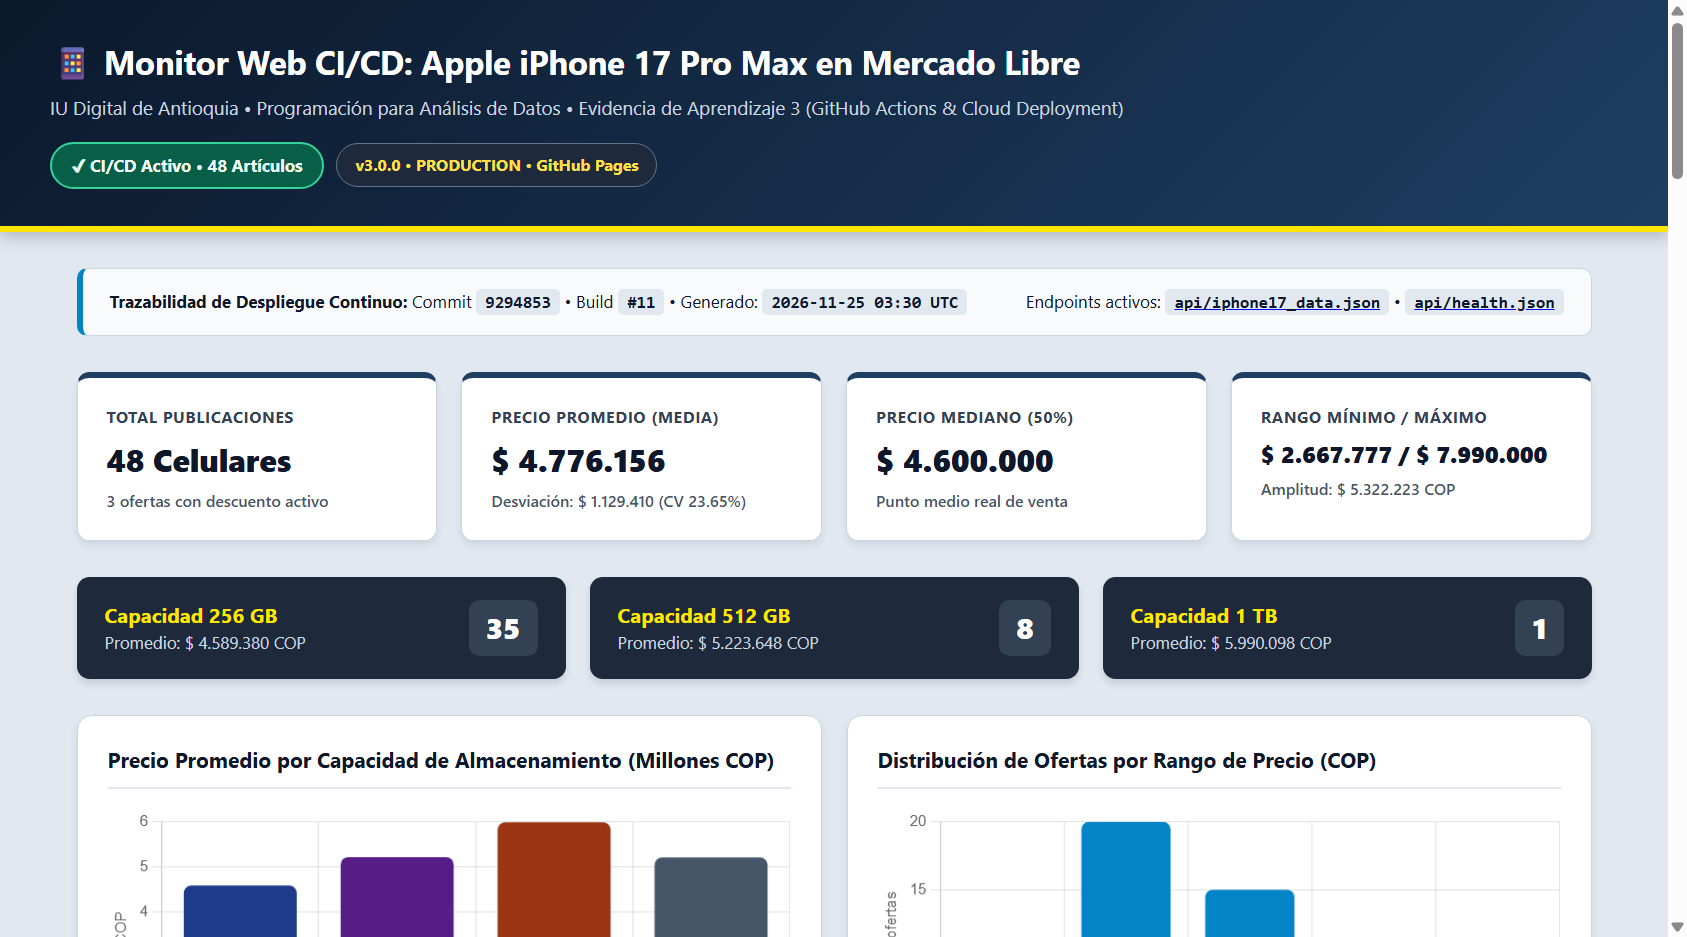

In [5]:
import json
import requests

url_app = "https://shenao356.github.io/mercadolibre-iphone17pm-shenao/"
url_health = url_app + "api/health.json"
url_runs = "https://api.github.com/repos/shenao356/mercadolibre-iphone17pm-shenao/actions/runs?per_page=3"

resp_app = requests.get(url_app, timeout=10)
resp_health = requests.get(url_health, timeout=10).json()
runs = requests.get(url_runs, timeout=10).json().get("workflow_runs", [])

print(f"HTTP Status Aplicación Web GitHub Pages: {resp_app.status_code} OK")
print("=== ENDPOINT CLOUD /api/health.json ===")
print(json.dumps(resp_health, indent=2, ensure_ascii=False))

print("\n=== ÚLTIMAS EJECUCIONES VERIFICADAS EN GITHUB ACTIONS ===")
for r in runs:
    print(f"  Run #{r['run_number']} | {r['name']} | status={r['status']} | conclusion={r['conclusion']} | commit={r['head_sha'][:7]}")

---
## 7. Evidencia Visual Complementaria: Gráficas en Producción y GitHub Actions

Mostramos las capturas verificadas de las gráficas interactivas desplegadas y del historial exitoso en GitHub Actions.

Captura 2: Gráficas Chart.js y Catálogo Interactivo en Producción (GitHub Pages)

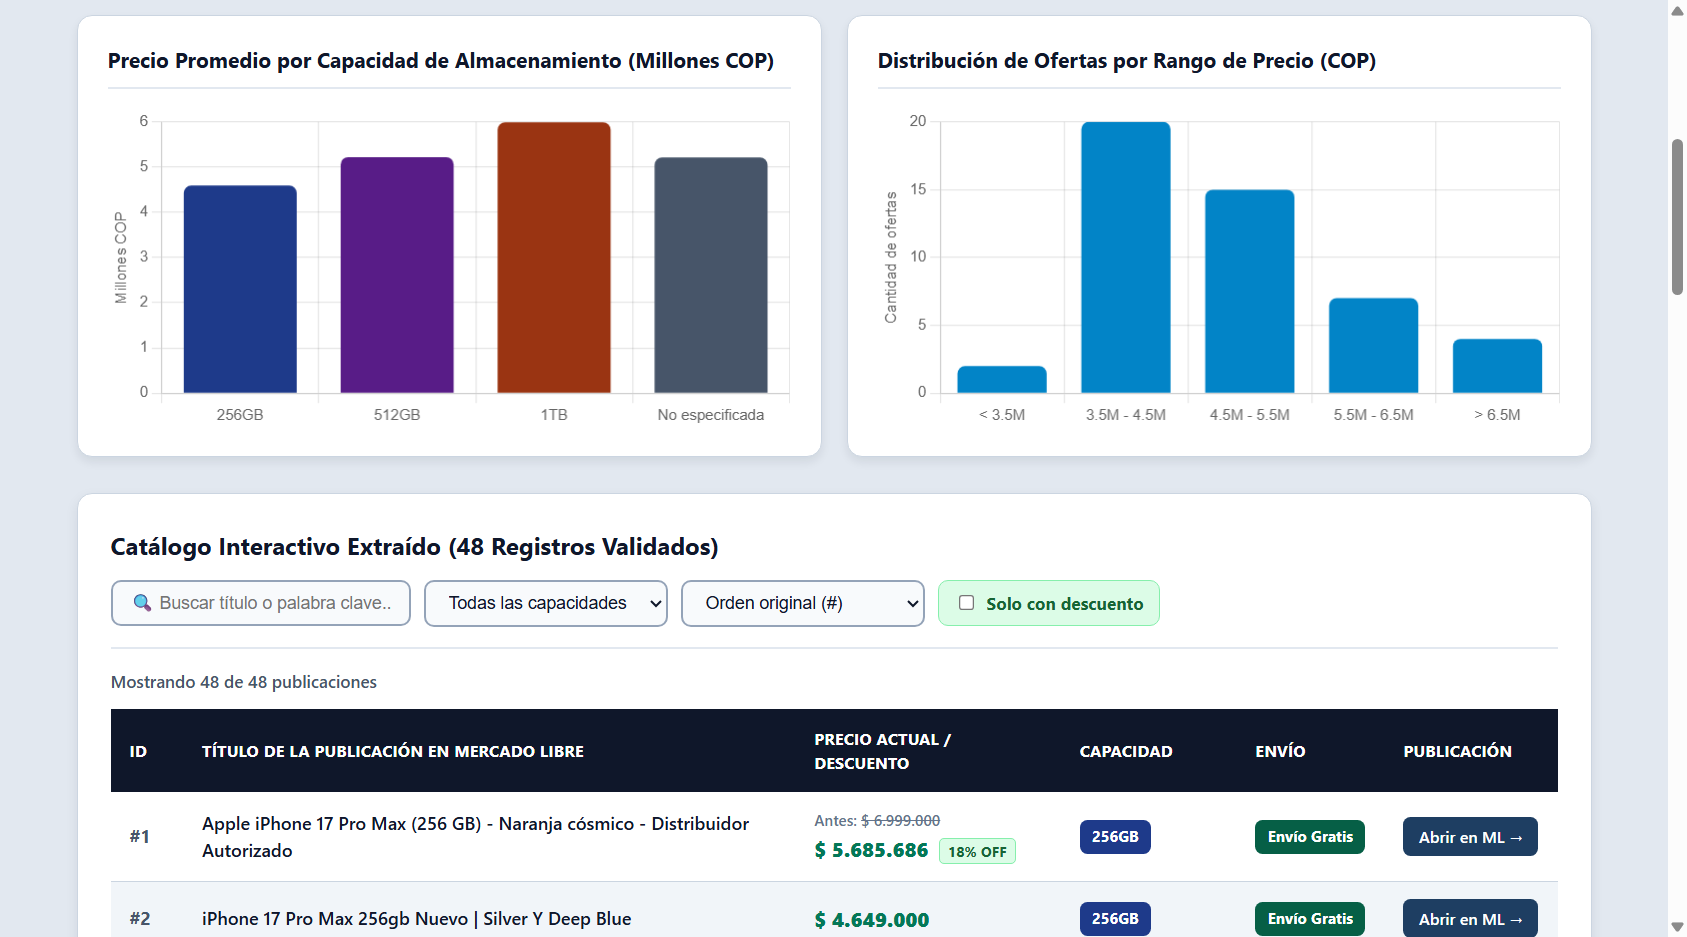

In [6]:
from IPython.display import Image, display

print("Captura 2: Gráficas Chart.js y Catálogo Interactivo en Producción (GitHub Pages)")
display(Image(filename="docs/screenshots/02_webapp_graficas_catalogo.png"))

Captura 3: Ejecuciones Exitosas en GitHub Actions (pages build and deployment #10)

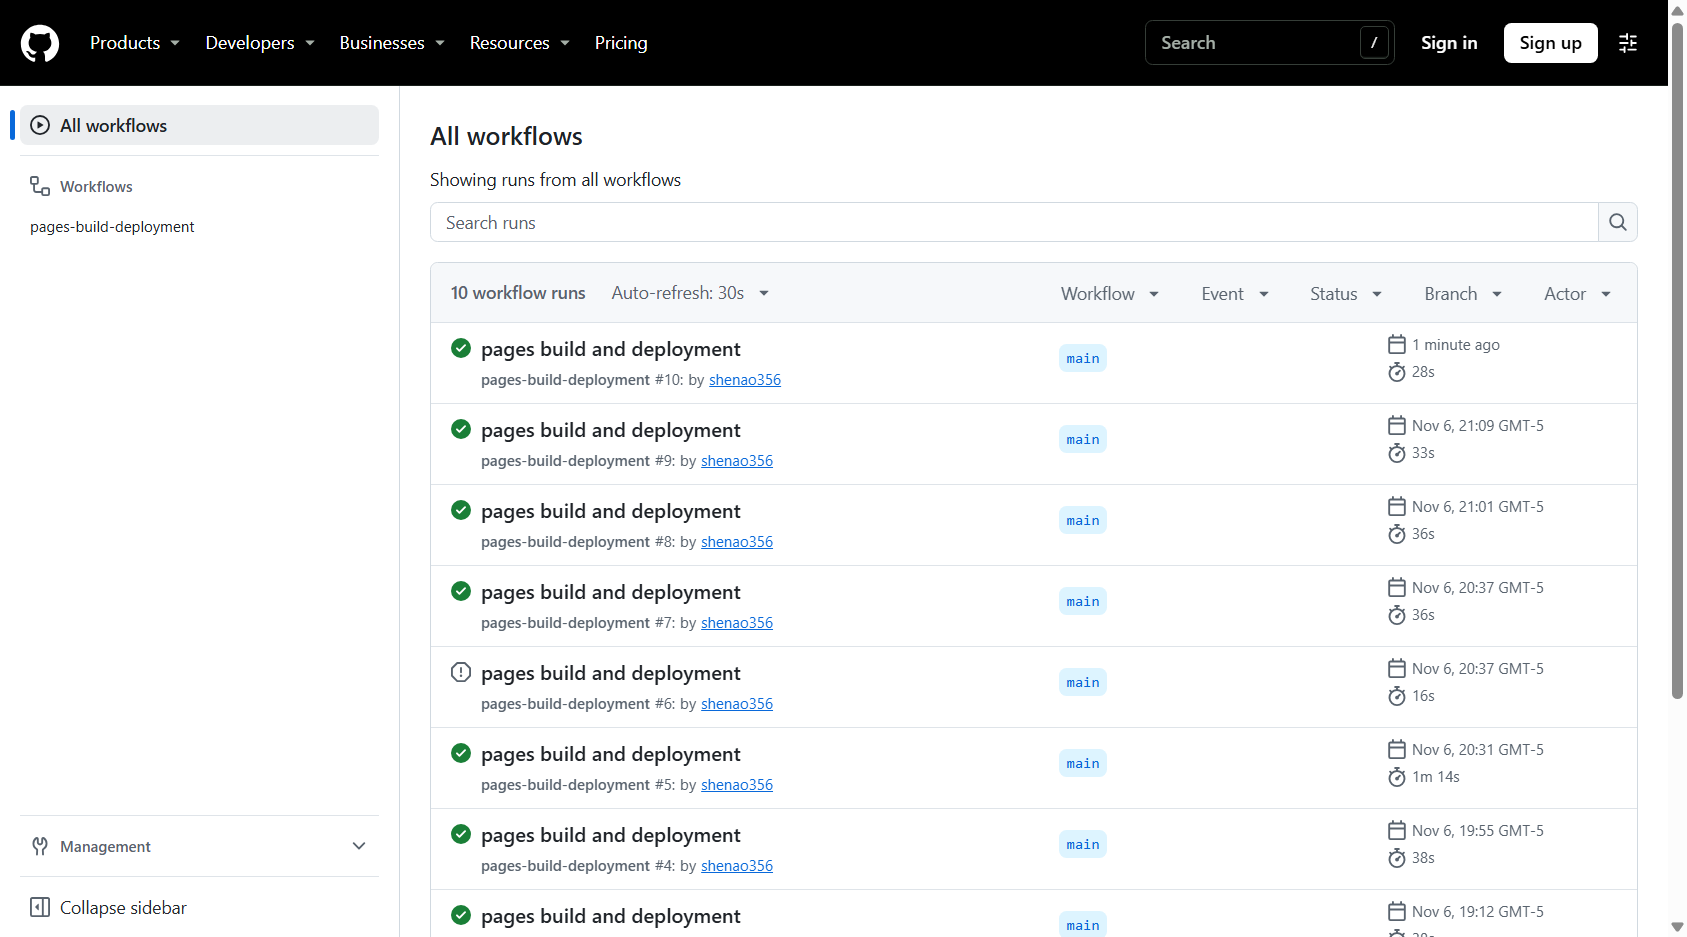

In [7]:
from IPython.display import Image, display

print("Captura 3: Ejecuciones Exitosas en GitHub Actions (pages build and deployment #10)")
display(Image(filename="docs/screenshots/03_github_actions_runs.png"))

---
## 8. Conclusiones y Referencias Bibliográficas (APA 7.ª Edición)

### Conclusiones
1. **Automatización CI/CD verificable:** El pipeline de 3 etapas y la suite de **14 pruebas automatizadas** (`OK` en `0,642 s`) aseguran calidad continua sobre el scraper, los endpoints REST y el paquete web antes de su publicación en la nube.
2. **Despliegue continuo real y portable:** La aplicación web v3.0.0 y sus endpoints JSON se encuentran en línea en **GitHub Pages** (`HTTP 200`, workflow `#10` exitoso), complementados por `Dockerfile`, `render.yaml` y `.env.example` para portabilidad hacia contenedores o PaaS.
3. **Coherencia analítica:** Los 48 registros del **iPhone 17 Pro Max** promedian **$ 4.776.156 COP** (mediana `$ 4.600.000 COP`), liderados en volumen por la versión de 256 GB (72,9 %, promedio `$ 4.589.380 COP`).

### Referencias Bibliográficas
* Apple Inc. (2026). *iPhone: Especificaciones técnicas y modelos comerciales*. https://www.apple.com/co/iphone/
* Chacon, S., & Straub, B. (2014). *Pro Git* (2nd ed.). Apress. https://git-scm.com/book/es/v2
* Forsgren, N., Humble, J., & Kim, G. (2018). *Accelerate: The science of lean software and DevOps*. IT Revolution Press.
* GitHub Inc. (2026). *GitHub Actions documentation*. https://docs.github.com/es/actions
* Humble, J., & Farley, D. (2010). *Continuous delivery: Reliable software releases through build, test, and deployment automation*. Addison-Wesley Professional.
* Kim, G., Humble, J., Debois, P., Willis, J., & Forsgren, N. (2021). *The DevOps handbook* (2nd ed.). IT Revolution Press.
* Mitchell, R. (2018). *Web scraping with Python* (2nd ed.). O'Reilly Media.